
--- Starting Training (Latent Dim: 100) ---
Epoch 0: [D loss: 0.9991, acc: 16.41%] [G loss: 0.6953]


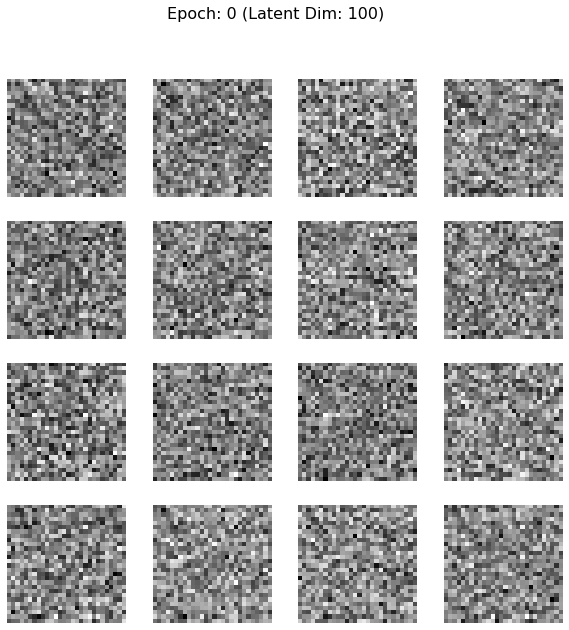

Epoch 500: [D loss: 0.5568, acc: 75.78%] [G loss: 1.0134]


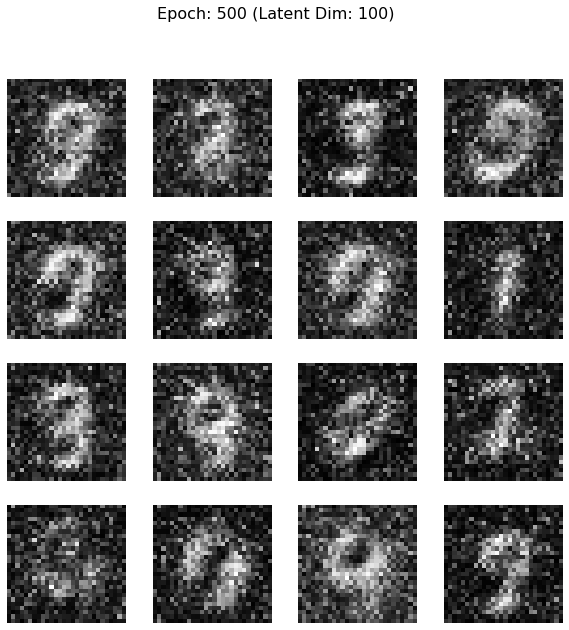

Epoch 1000: [D loss: 0.6112, acc: 65.62%] [G loss: 1.2670]


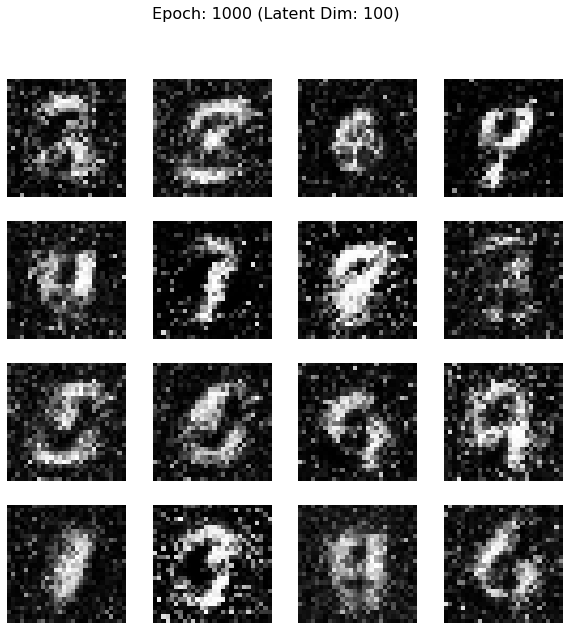

Epoch 1500: [D loss: 0.4951, acc: 82.03%] [G loss: 1.3980]


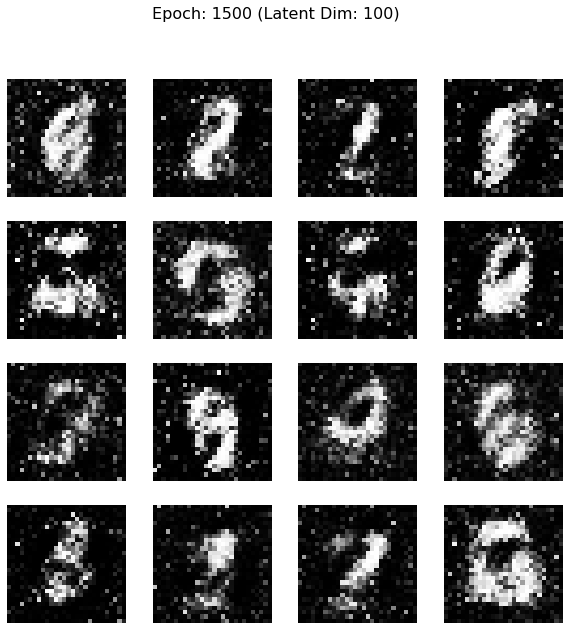

Epoch 2000: [D loss: 0.4619, acc: 79.69%] [G loss: 1.5023]


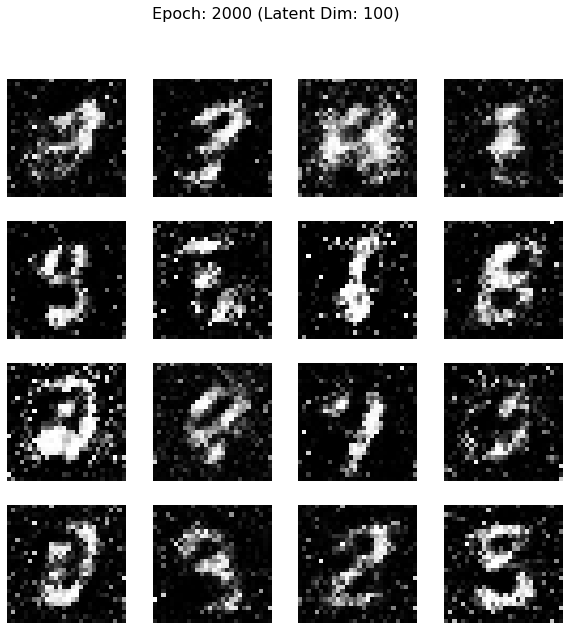

Epoch 2500: [D loss: 0.3507, acc: 90.62%] [G loss: 1.6345]


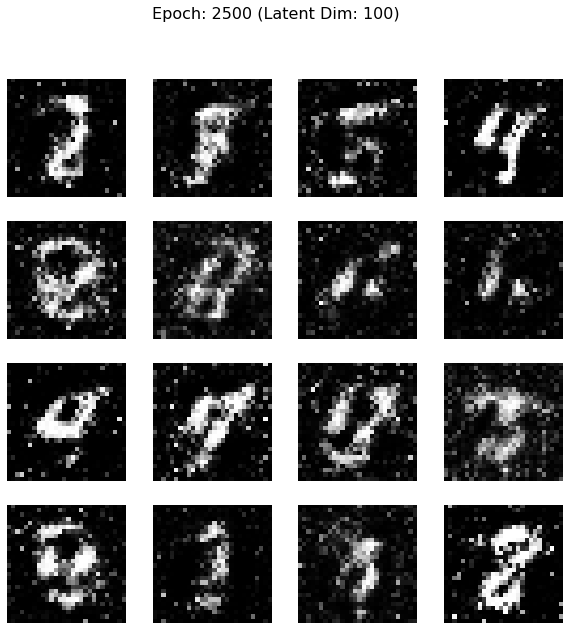

Epoch 3000: [D loss: 0.4952, acc: 76.56%] [G loss: 1.5296]


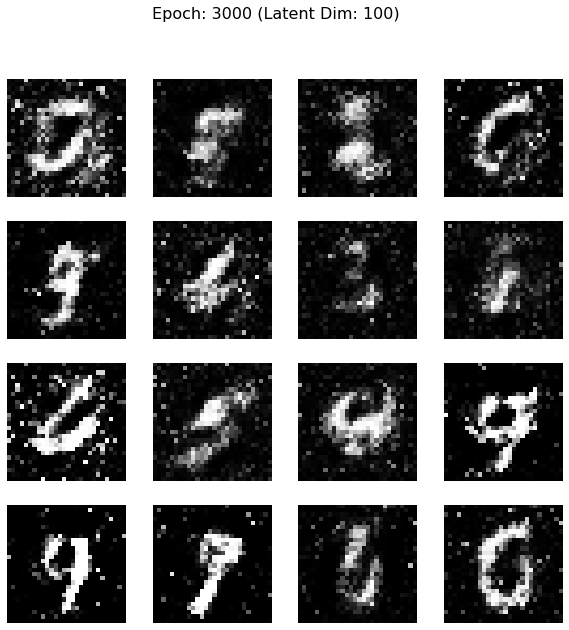

Epoch 3500: [D loss: 0.4934, acc: 81.25%] [G loss: 1.2816]


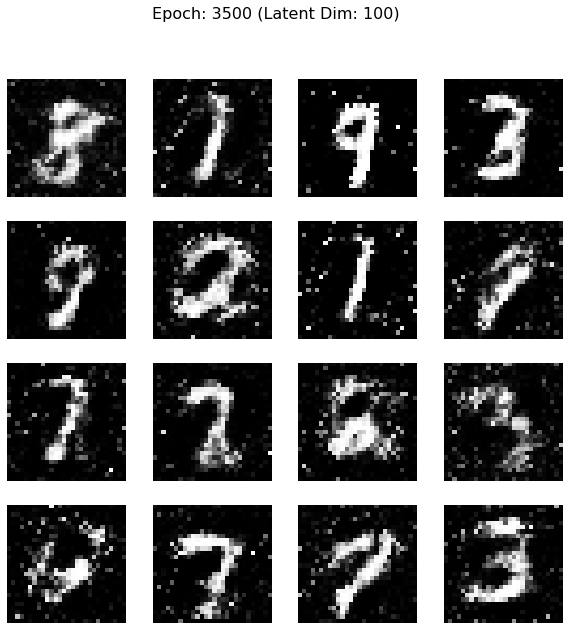

Epoch 4000: [D loss: 0.4898, acc: 83.59%] [G loss: 1.3223]


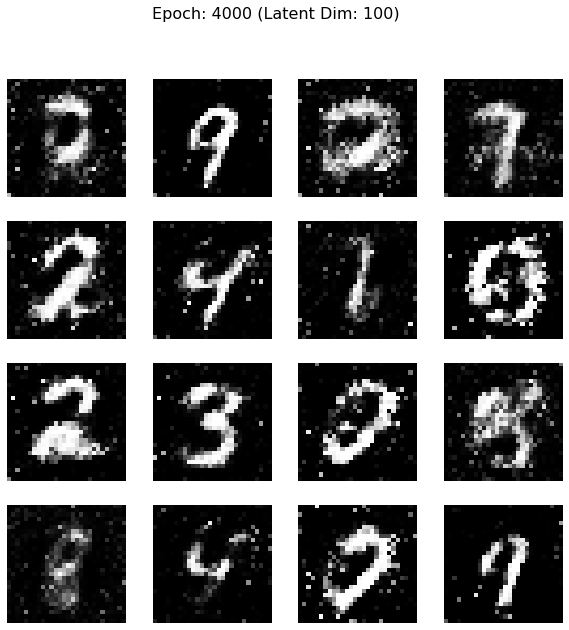

Epoch 4500: [D loss: 0.5132, acc: 75.00%] [G loss: 1.2567]


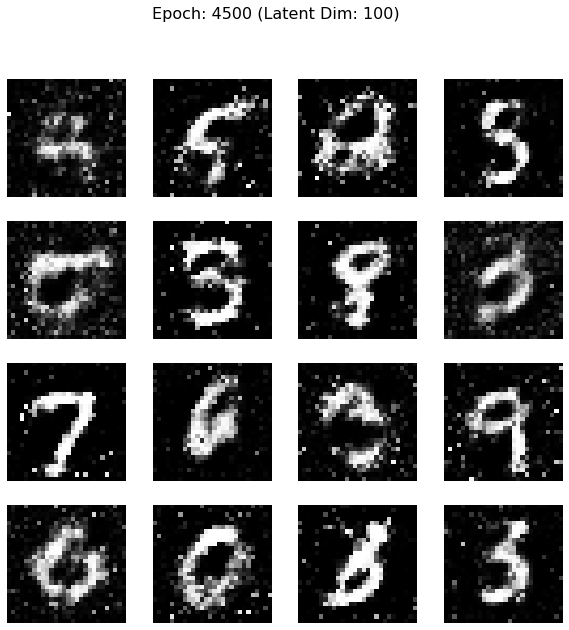

Epoch 5000: [D loss: 0.5696, acc: 70.31%] [G loss: 1.1544]


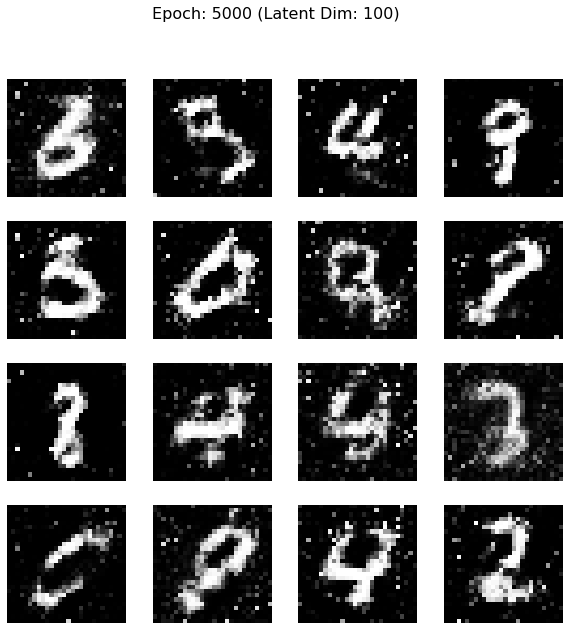

Epoch 5500: [D loss: 0.4399, acc: 84.38%] [G loss: 1.2163]


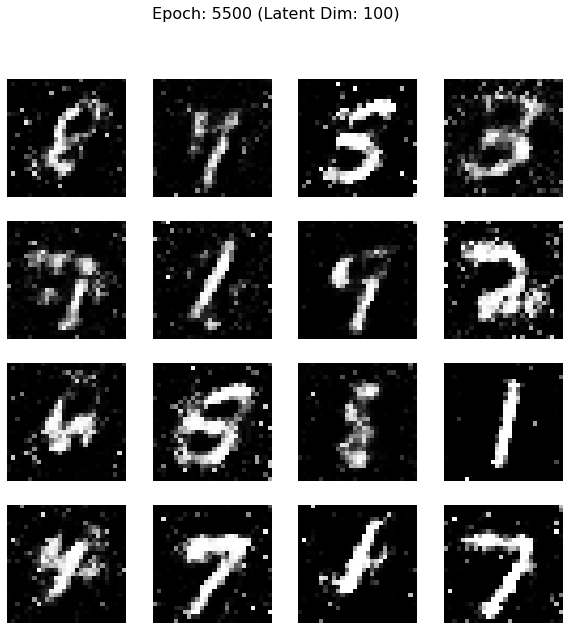

Epoch 6000: [D loss: 0.5292, acc: 75.00%] [G loss: 1.1723]


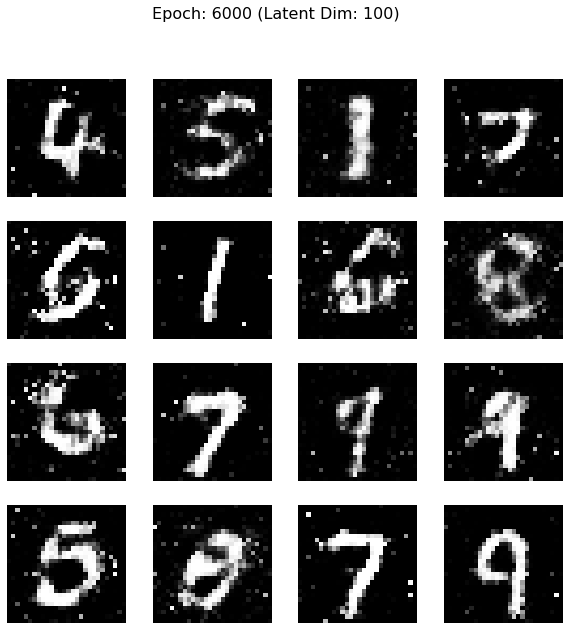

Epoch 6500: [D loss: 0.5079, acc: 75.78%] [G loss: 1.2162]


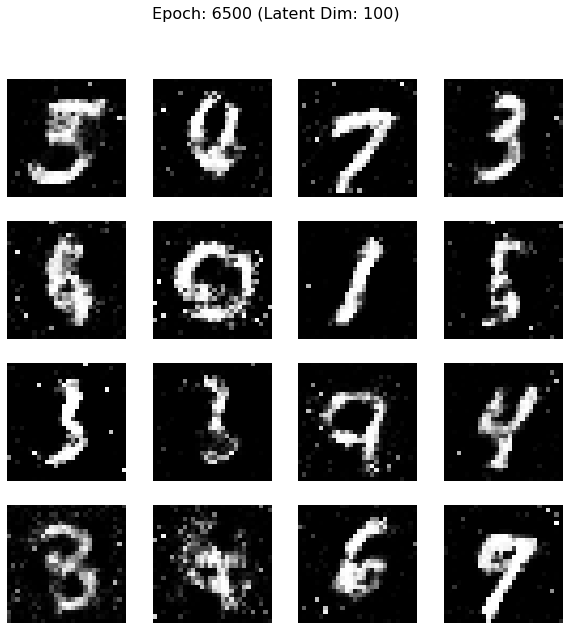

Epoch 7000: [D loss: 0.5245, acc: 70.31%] [G loss: 1.1563]


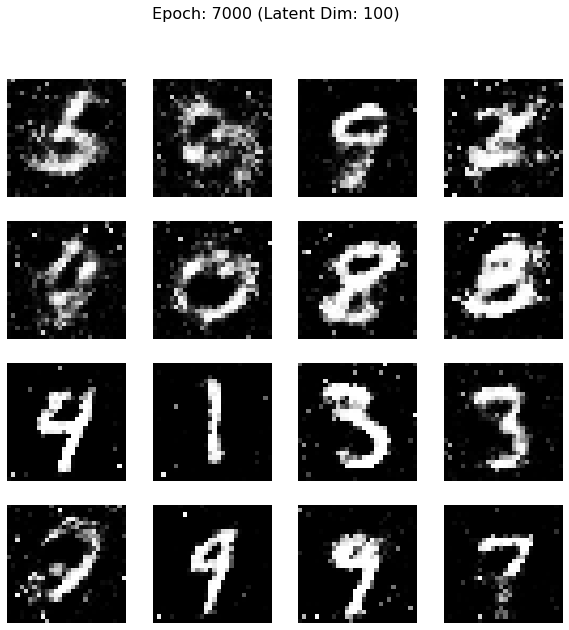

Epoch 7500: [D loss: 0.5448, acc: 71.09%] [G loss: 1.2421]


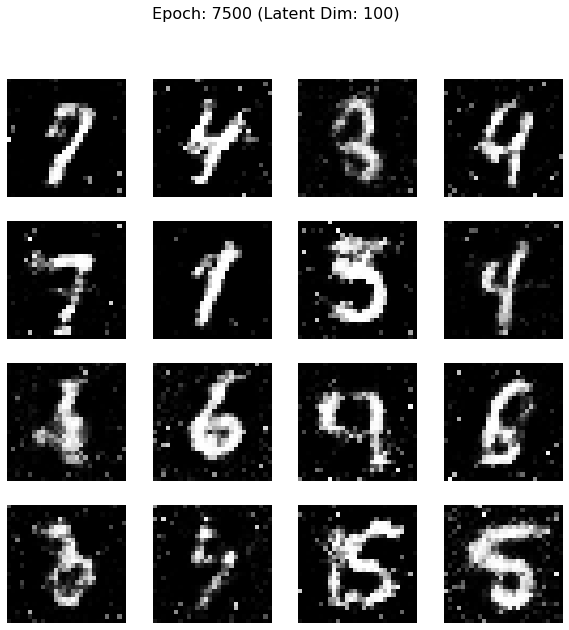

Epoch 8000: [D loss: 0.4582, acc: 83.59%] [G loss: 1.1276]


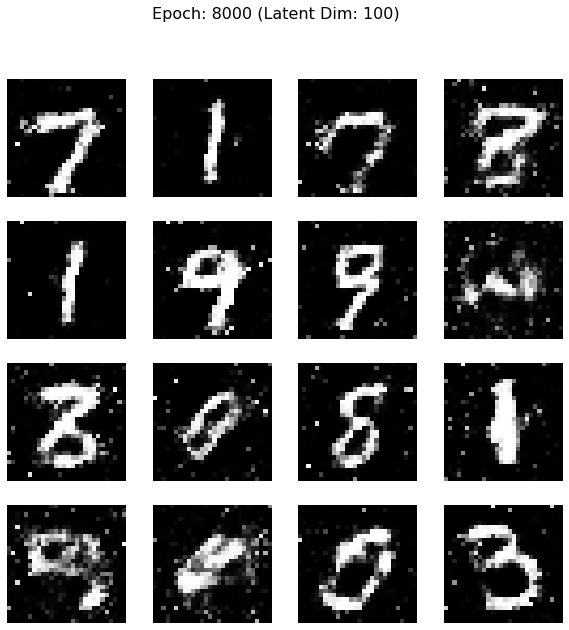

Epoch 8500: [D loss: 0.6131, acc: 64.84%] [G loss: 1.2304]


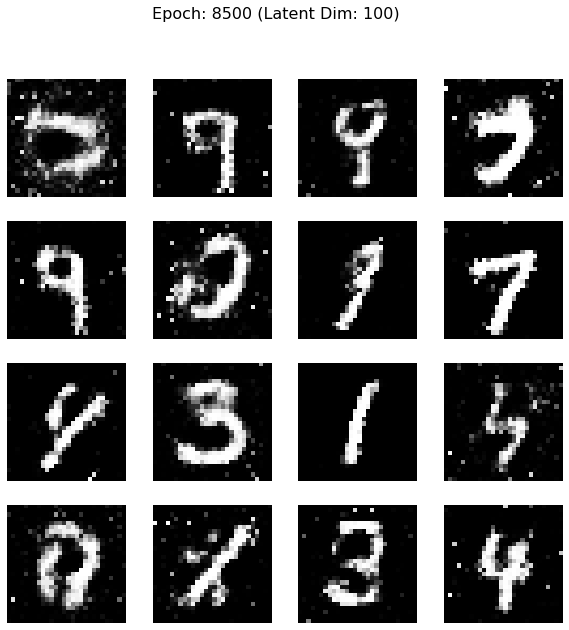

Epoch 9000: [D loss: 0.6103, acc: 67.97%] [G loss: 1.2176]


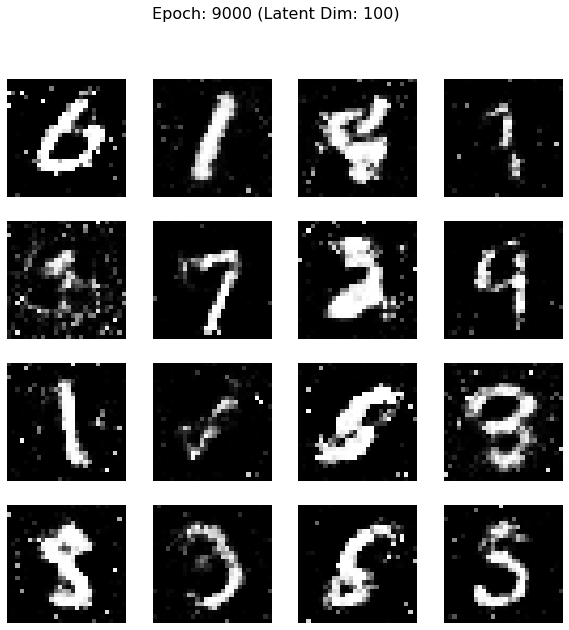

Epoch 9500: [D loss: 0.5179, acc: 72.66%] [G loss: 1.2885]


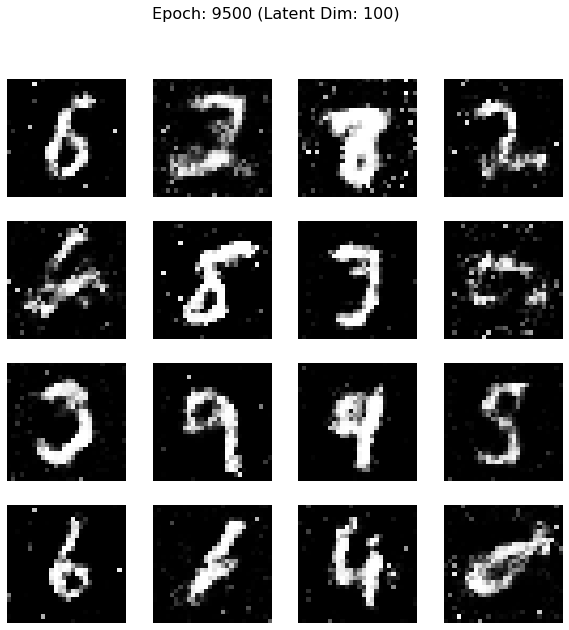

Epoch 10000: [D loss: 0.6529, acc: 59.38%] [G loss: 1.2625]


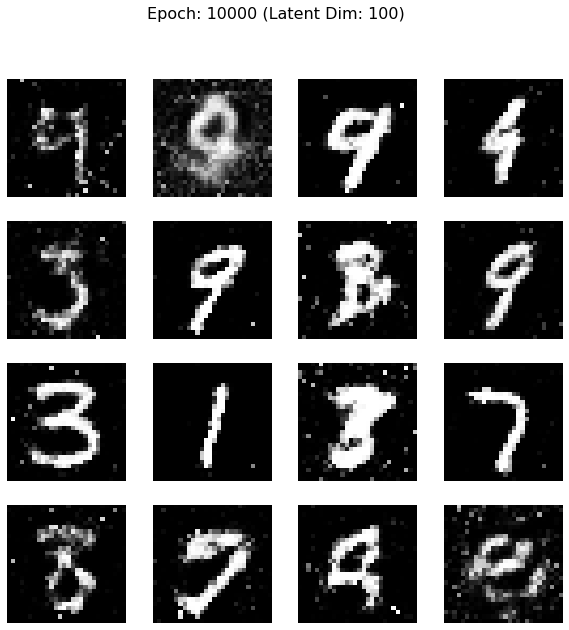

Epoch 10500: [D loss: 0.4850, acc: 77.34%] [G loss: 1.1886]


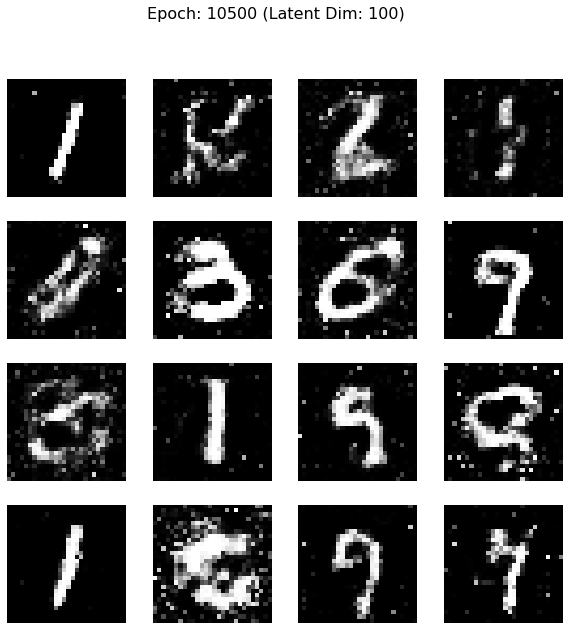

Epoch 11000: [D loss: 0.5416, acc: 71.88%] [G loss: 1.3061]


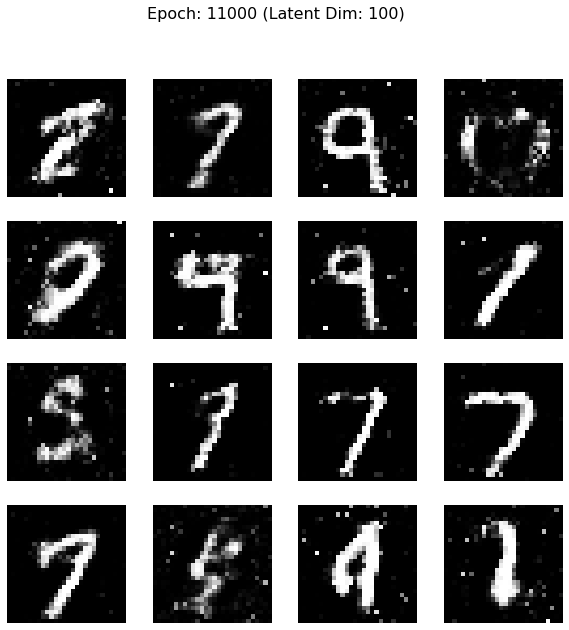

Epoch 11500: [D loss: 0.5413, acc: 72.66%] [G loss: 1.2366]


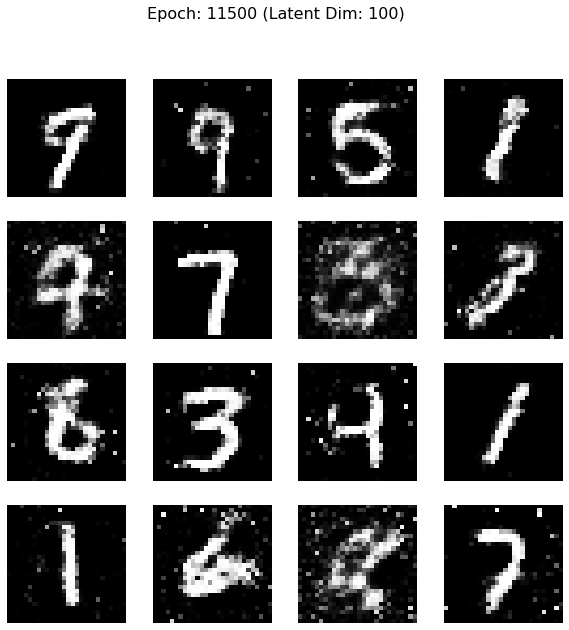

Epoch 12000: [D loss: 0.5446, acc: 76.56%] [G loss: 1.2636]


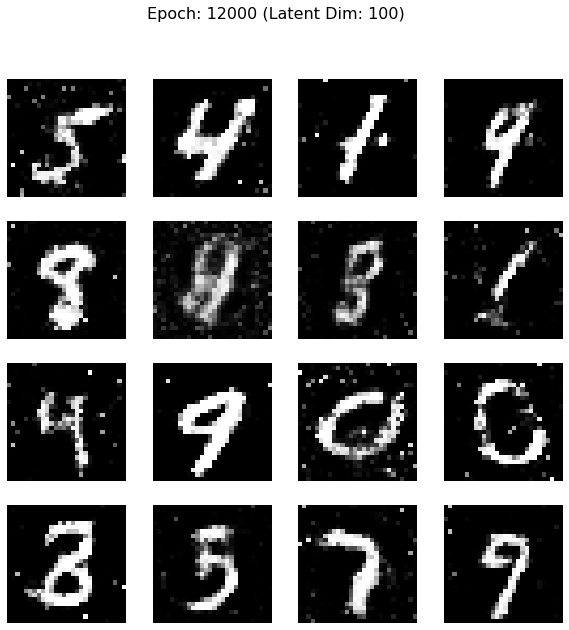

Epoch 12500: [D loss: 0.5258, acc: 72.66%] [G loss: 1.3383]


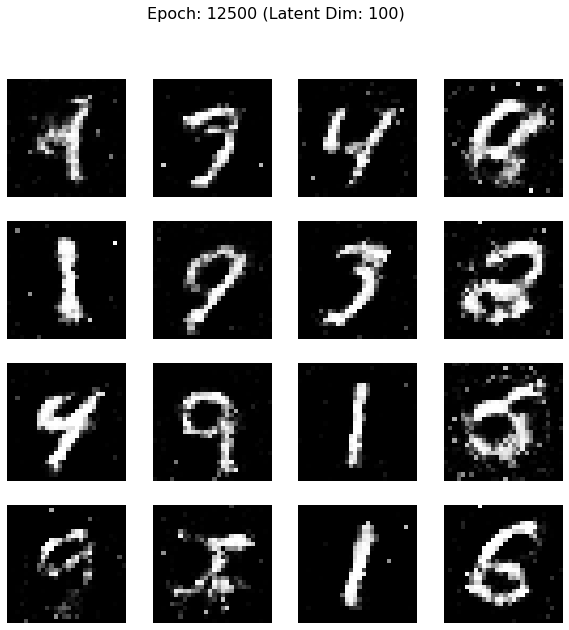

Epoch 13000: [D loss: 0.5033, acc: 73.44%] [G loss: 1.2356]


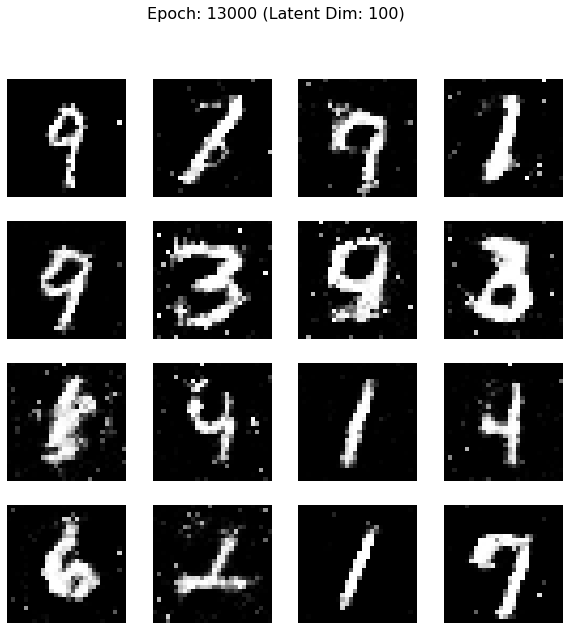

Epoch 13500: [D loss: 0.5278, acc: 67.97%] [G loss: 1.2129]


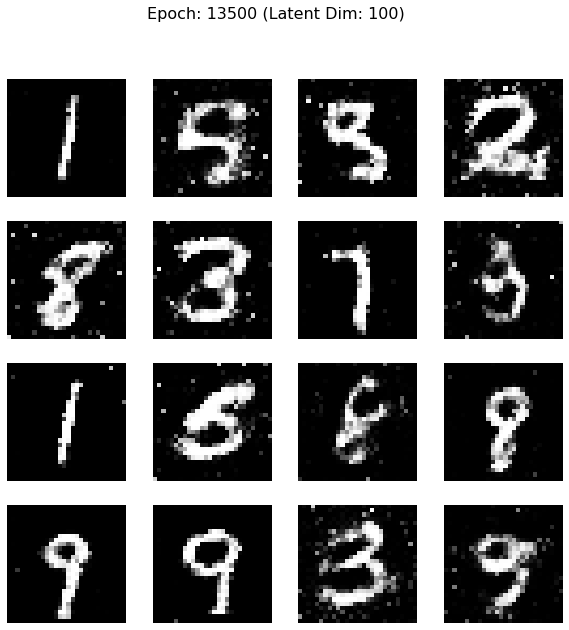

Epoch 14000: [D loss: 0.5786, acc: 66.41%] [G loss: 1.4265]


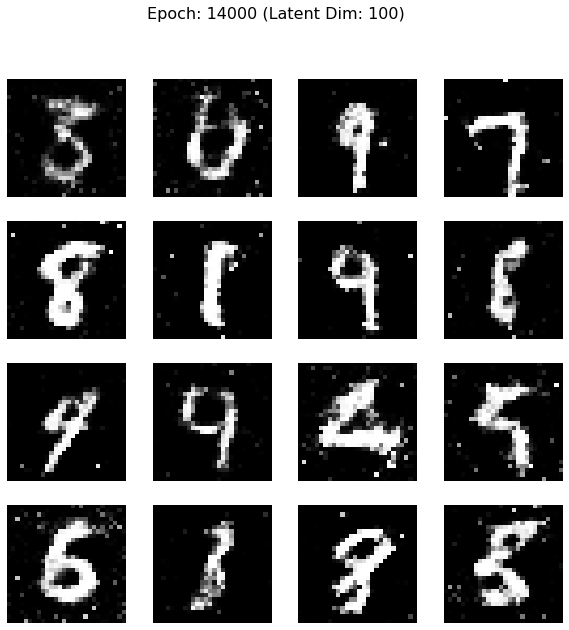

Epoch 14500: [D loss: 0.5120, acc: 77.34%] [G loss: 1.3117]


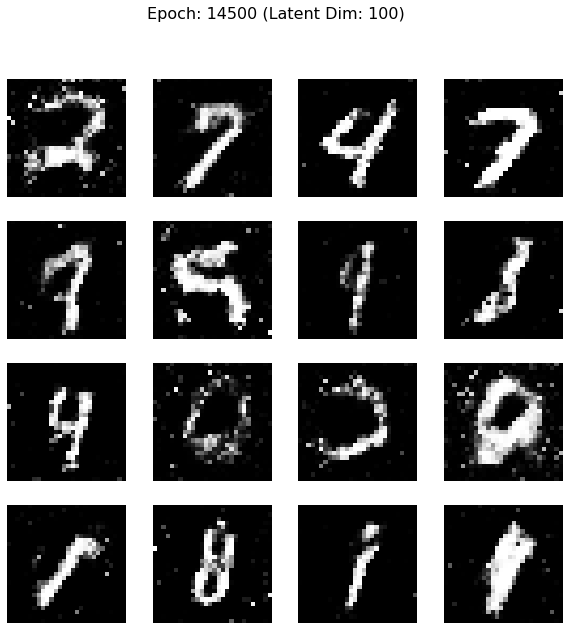

Epoch 15000: [D loss: 0.5196, acc: 71.88%] [G loss: 1.3339]


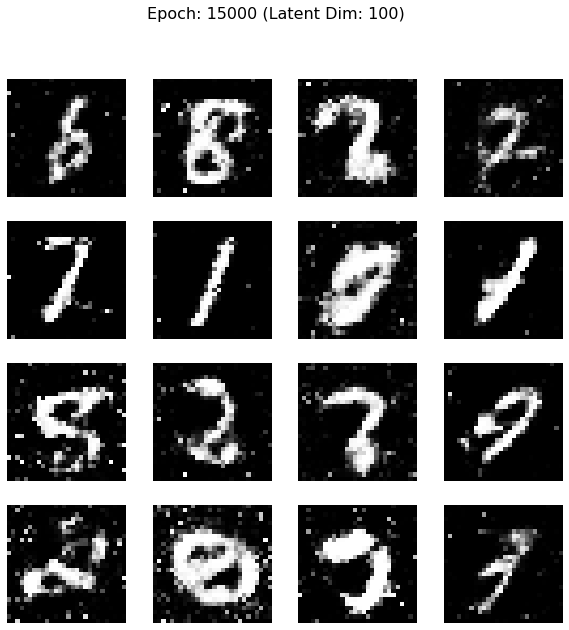

Epoch 15500: [D loss: 0.5521, acc: 70.31%] [G loss: 1.2672]


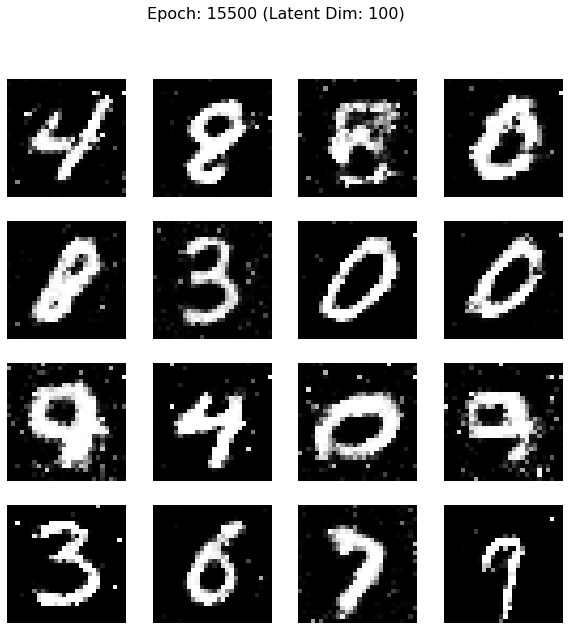

Epoch 16000: [D loss: 0.5688, acc: 75.78%] [G loss: 1.3663]


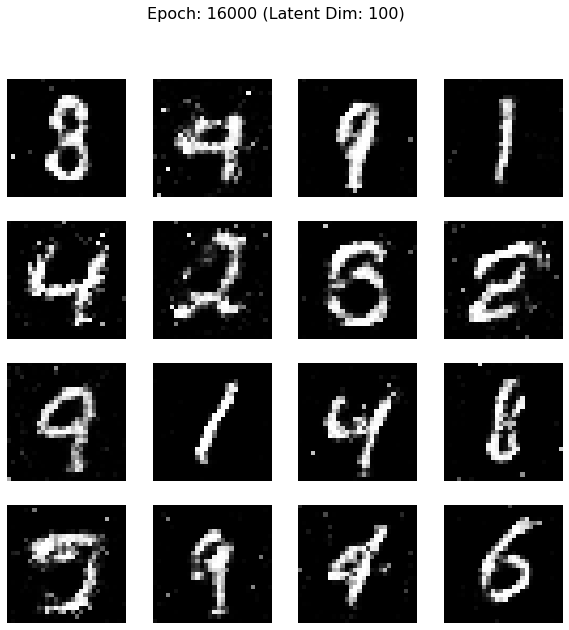

Epoch 16500: [D loss: 0.5170, acc: 71.09%] [G loss: 1.3124]


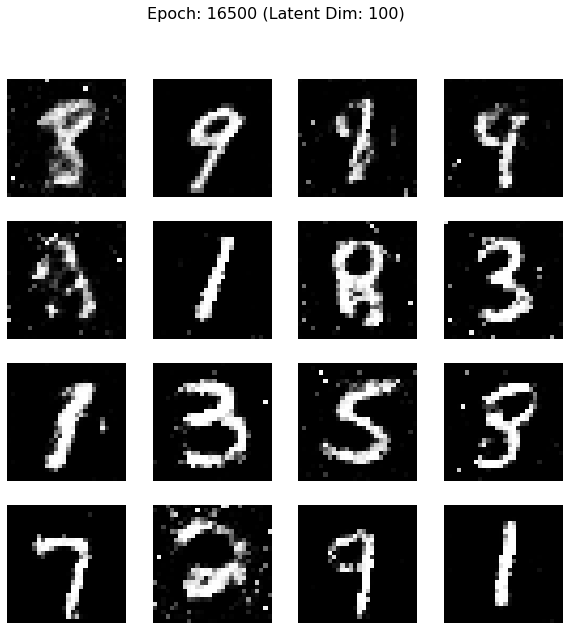

Epoch 17000: [D loss: 0.6161, acc: 67.97%] [G loss: 1.2597]


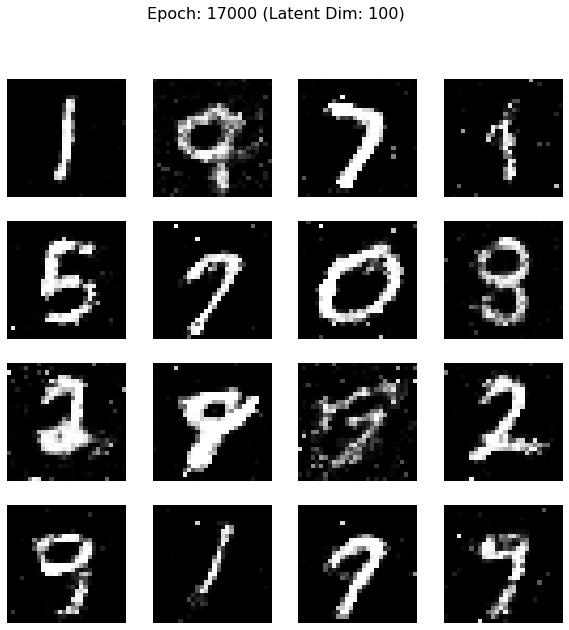

Epoch 17500: [D loss: 0.5548, acc: 73.44%] [G loss: 1.4282]


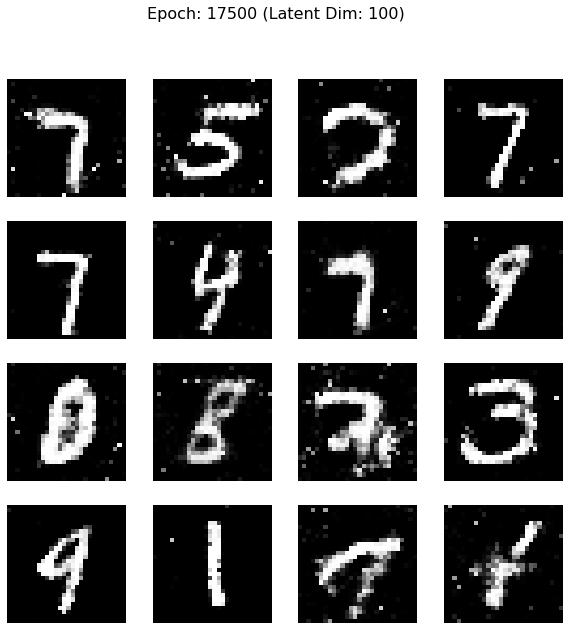

Epoch 18000: [D loss: 0.5227, acc: 77.34%] [G loss: 1.2891]


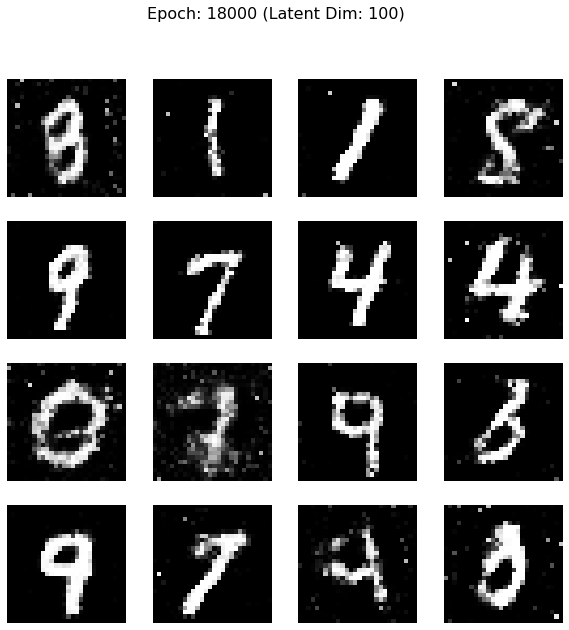

Epoch 18500: [D loss: 0.5214, acc: 75.00%] [G loss: 1.2491]


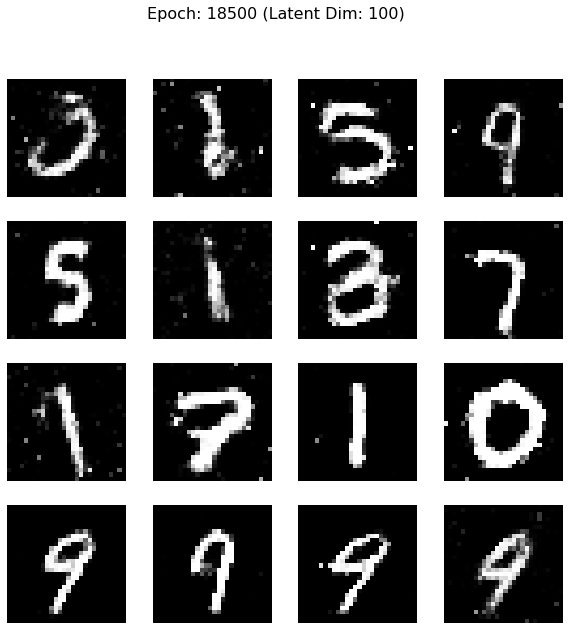

Epoch 19000: [D loss: 0.5430, acc: 75.00%] [G loss: 1.3639]


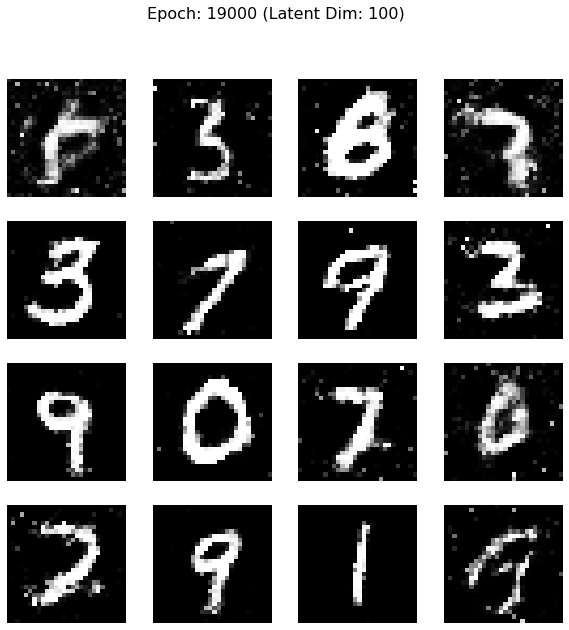

Epoch 19500: [D loss: 0.5584, acc: 67.19%] [G loss: 1.2976]


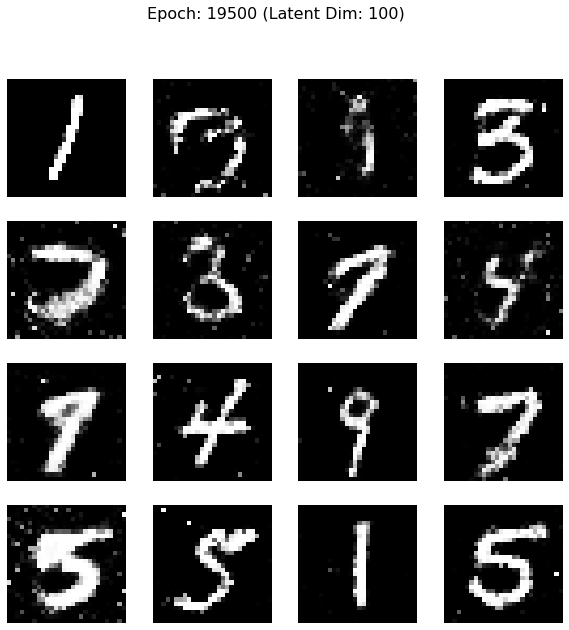

Epoch 20000: [D loss: 0.4770, acc: 79.69%] [G loss: 1.4020]


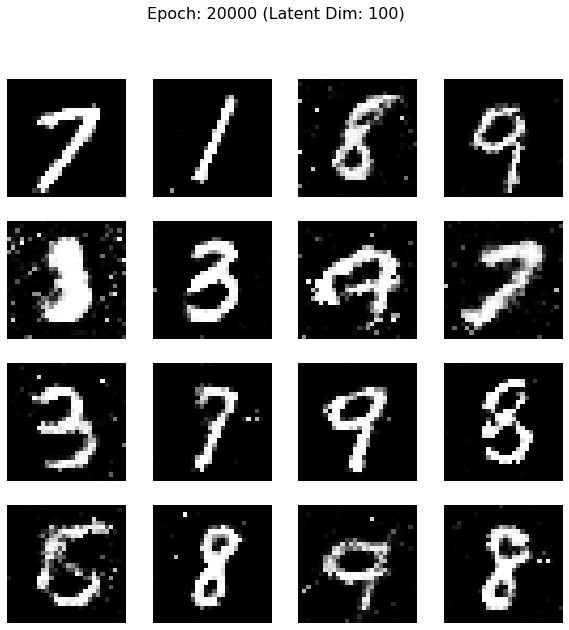

Epoch 20500: [D loss: 0.5226, acc: 74.22%] [G loss: 1.4055]


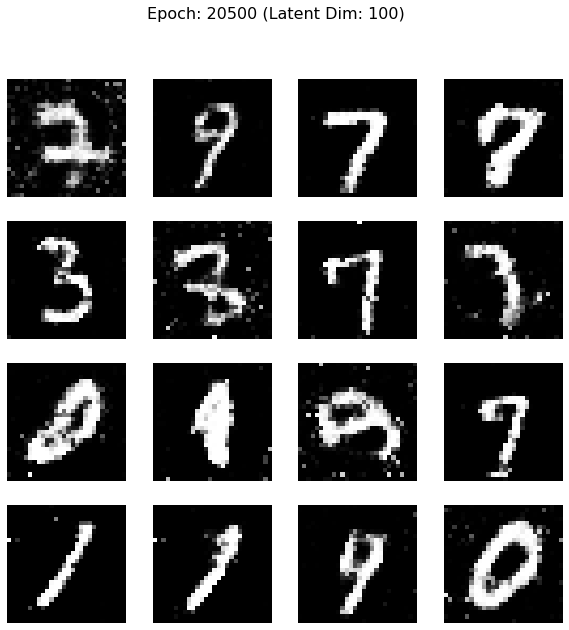

Epoch 21000: [D loss: 0.5335, acc: 69.53%] [G loss: 1.4563]


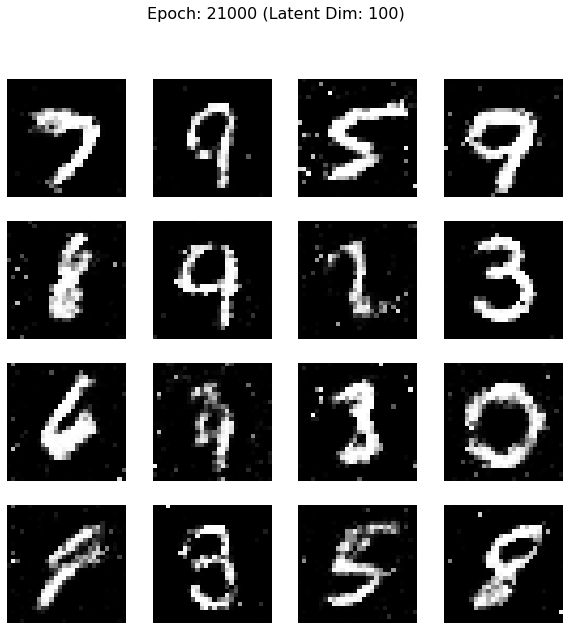

Epoch 21500: [D loss: 0.5079, acc: 75.78%] [G loss: 1.3427]


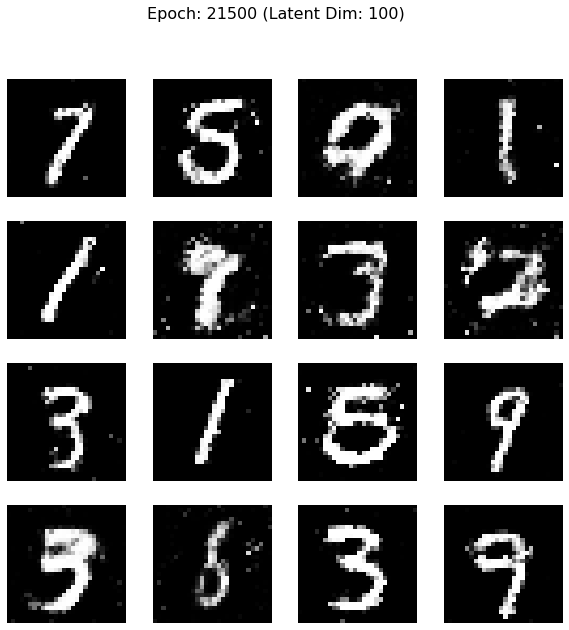

Epoch 22000: [D loss: 0.4773, acc: 76.56%] [G loss: 1.3676]


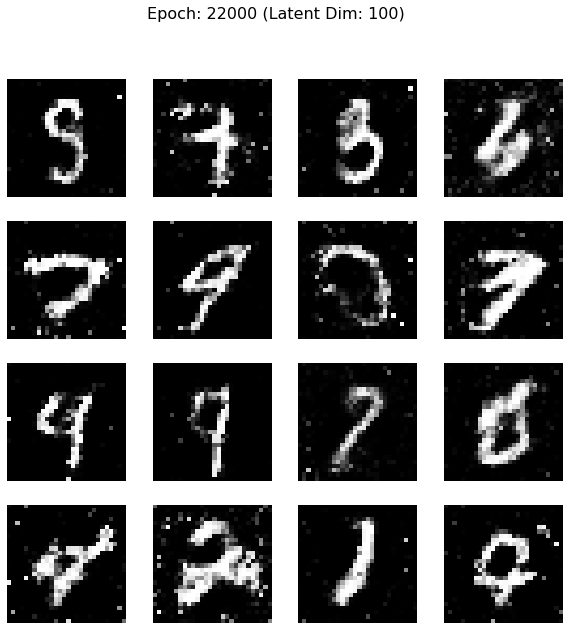

Epoch 22500: [D loss: 0.4703, acc: 81.25%] [G loss: 1.5404]


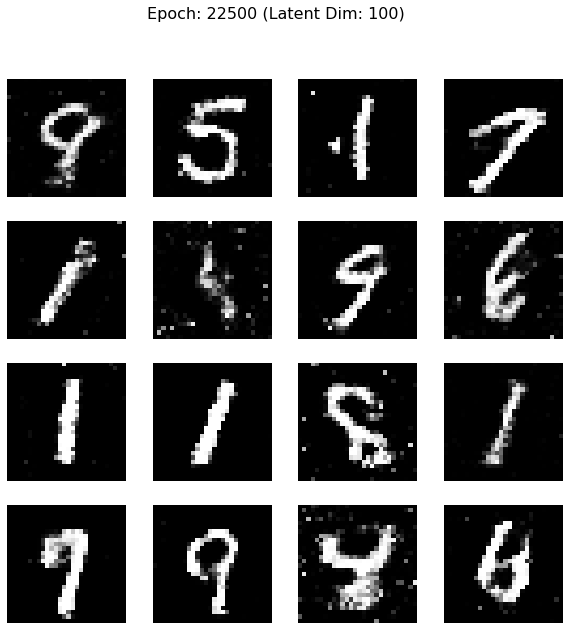

Epoch 23000: [D loss: 0.5780, acc: 69.53%] [G loss: 1.2824]


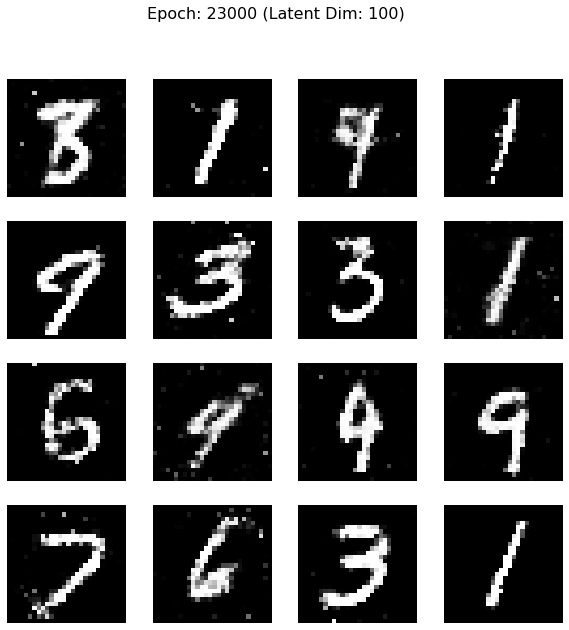

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# --- Define Hyperparameters ---
LATENT_DIM = 100
IMG_SHAPE = (28, 28, 1)
IMG_FLAT_DIM = 28 * 28

# --- Build the Generator Model ---
def build_generator():
    model = tf.keras.models.Sequential(name="Generator")
    
    # First layer
    model.add(tf.keras.layers.Dense(256, input_dim=LATENT_DIM))
    model.add(tf.keras.layers.LeakyReLU(alpha=0.2))
    
    # Second layer
    model.add(tf.keras.layers.Dense(512))
    model.add(tf.keras.layers.LeakyReLU(alpha=0.2))
    
    # Output layer
    model.add(tf.keras.layers.Dense(IMG_FLAT_DIM, activation='tanh'))
    
    # Reshape to image format
    model.add(tf.keras.layers.Reshape(IMG_SHAPE))
    
    return model

# --- Build the Discriminator Model ---
def build_discriminator():
    model = tf.keras.models.Sequential(name="Discriminator")
    
    # Flatten layer
    model.add(tf.keras.layers.Flatten(input_shape=IMG_SHAPE))
    
    # First dense layer
    model.add(tf.keras.layers.Dense(512))
    model.add(tf.keras.layers.LeakyReLU(alpha=0.2))
    
    # Second dense layer
    model.add(tf.keras.layers.Dense(256))
    model.add(tf.keras.layers.LeakyReLU(alpha=0.2))
    
    # Output (decision) layer
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    
    return model

# --- Utility function to save AND SHOW generated images ---
def save_and_show_imgs(epoch, generator, examples=16, dim=(4, 4), figsize=(10, 10)):
    noise = np.random.normal(0, 1, (examples, LATENT_DIM))
    gen_imgs = generator.predict(noise, verbose=0)
    
    # Rescale images 0-1
    gen_imgs = 0.5 * gen_imgs + 0.5
    
    fig, axs = plt.subplots(dim[0], dim[1], figsize=figsize)
    # Add a title to the figure
    fig.suptitle(f"Epoch: {epoch} (Latent Dim: {LATENT_DIM})", fontsize=16)
    
    cnt = 0
    for i in range(dim[0]):
        for j in range(dim[1]):
            axs[i, j].imshow(gen_imgs[cnt, :, :, 0], cmap='gray')
            axs[i, j].axis('off')
            cnt += 1
    
    # --- MODIFIED SECTION ---
    # Create folder name based on LATENT_DIM
    folder_name = f"images_latent_{LATENT_DIM}"
    
    # Ensure the dynamic directory exists
    os.makedirs(folder_name, exist_ok=True)
    
    # Save the figure to the dynamic folder
    fig.savefig(f"{folder_name}/mnist_{epoch:04d}.png")
    # --- END MODIFIED SECTION ---
    
    # --- Show the plot on screen ---
    plt.show(block=False)  # Show the window without pausing the script
    plt.pause(1)           # Display the window for 1 second
    plt.close()            # Close the window to continue training
    # ------------------------------

# --- Training Hyperparameters ---
EPOCHS = 30000
BATCH_SIZE = 128
SAVE_INTERVAL = 500

# --- Model Compilation ---
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

# 5a. Build and Compile the Discriminator
discriminator = build_discriminator()
discriminator.compile(loss='binary_crossentropy',
                      optimizer=optimizer,
                      metrics=['accuracy'])

# 5b. Build the Generator
generator = build_generator()

# 5c. Freeze Discriminator for combined model training
discriminator.trainable = False

# 5d. Create and compile the combined GAN model
gan_model = tf.keras.models.Sequential(name="GAN")
gan_model.add(generator)
gan_model.add(discriminator)
gan_model.compile(loss='binary_crossentropy', optimizer=optimizer)

# --- Load and Preprocess Data ---
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Reshape and normalize
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1).astype('float32')
x_train = (x_train - 127.5) / 127.5  # Normalize to [-1, 1]

# --- Setting up labels ---
# Labels for real images (Target: 1)
real_labels = np.ones((BATCH_SIZE // 2, 1))
# Labels for fake images (Target: 0)
fake_labels = np.zeros((BATCH_SIZE // 2, 1))

# --- The Training Loop ---
print(f"\n--- Starting Training (Latent Dim: {LATENT_DIM}) ---")
for epoch in range(EPOCHS):
    
    # --- Part 1: Train the Discriminator ---
    
    # 1a. Train on REAL images
    idx = np.random.randint(0, x_train.shape[0], BATCH_SIZE // 2)
    real_images = x_train[idx]
    
    d_loss_real = discriminator.train_on_batch(real_images, real_labels)
    
    # 1b. Train on FAKE images
    noise = np.random.normal(0, 1, (BATCH_SIZE // 2, LATENT_DIM))
    fake_images = generator.predict(noise, verbose=0)
    
    d_loss_fake = discriminator.train_on_batch(fake_images, fake_labels)
    
    # Average discriminator loss
    d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

    # --- Part 2: Train the Generator ---
    
    # 2a. Prepare Full Batch Noise and Misleading Labels
    noise = np.random.normal(0, 1, (BATCH_SIZE, LATENT_DIM))
    generator_labels = np.ones((BATCH_SIZE, 1))
    
    # Train the Generator (via the combined model)
    g_loss = gan_model.train_on_batch(noise, generator_labels)

    # --- Progress saving ---
    if epoch % SAVE_INTERVAL == 0:
        print(f"Epoch {epoch}: [D loss: {d_loss[0]:.4f}, acc: {d_loss[1]*100:.2f}%] [G loss: {g_loss:.4f}]")
        # Call the new function that saves and shows
        save_and_show_imgs(epoch, generator)

print("--- Training Finished ---")